In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [6]:
# Load dataset
df = pd.read_csv('House Price Prediction Dataset.csv')

In [8]:
# Dataset information
print("Dataset Name: House Price Prediction Dataset")
print("Total Rows and Columns:", df.shape)

Dataset Name: House Price Prediction Dataset
Total Rows and Columns: (2000, 10)


In [9]:
# Display column names
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Location', 'Condition', 'Garage', 'Price']


In [10]:
# First five records
print("First Five Rows:")
print(df.head())

# Last five records
print("\nLast Five Rows:")
print(df.tail())

# Dataset shape
print("\nDataset Shape:")
print(df.shape)

# Data types
print("\nData Types:")
print(df.dtypes)

# Summary statistics
print("\nStatistical Summary:")
print(df.describe())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Rows:")
print(df.duplicated().sum())

First Five Rows:
   Id  Area  Bedrooms  Bathrooms  Floors  YearBuilt  Location  Condition  \
0   1  1360         5          4       3       1970  Downtown  Excellent   
1   2  4272         5          4       3       1958  Downtown  Excellent   
2   3  3592         2          2       3       1938  Downtown       Good   
3   4   966         4          2       2       1902  Suburban       Fair   
4   5  4926         1          4       2       1975  Downtown       Fair   

  Garage   Price  
0     No  149919  
1     No  424998  
2     No  266746  
3    Yes  244020  
4    Yes  636056  

Last Five Rows:
        Id  Area  Bedrooms  Bathrooms  Floors  YearBuilt  Location  Condition  \
1995  1996  4994         5          4       3       1923  Suburban       Poor   
1996  1997  3046         5          2       1       2019  Suburban       Poor   
1997  1998  1062         5          1       2       1903     Rural       Poor   
1998  1999  4062         3          1       2       1936     Urban  Exc

In [11]:
# Select input feature
X = df[['Area']]

# Select target variable
y = df['Price']

print("Input Feature (X):")
print(X.head())

print("\nTarget Variable (Y):")
print(y.head())

print("\nInput Shape:", X.shape)
print("Target Shape:", y.shape)

Input Feature (X):
   Area
0  1360
1  4272
2  3592
3   966
4  4926

Target Variable (Y):
0    149919
1    424998
2    266746
3    244020
4    636056
Name: Price, dtype: int64

Input Shape: (2000, 1)
Target Shape: (2000,)


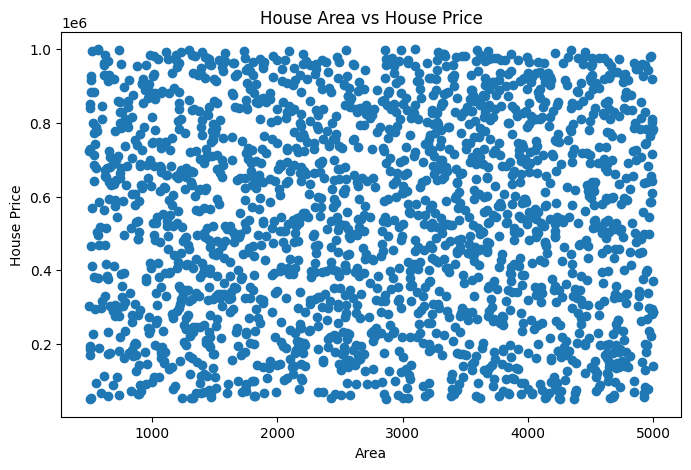

In [12]:
plt.figure(figsize=(8,5))

plt.scatter(X['Area'], y)

plt.title("House Area vs House Price")
plt.xlabel("Area")
plt.ylabel("House Price")

plt.show()

In [13]:
#split the data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (1600, 1)
Testing Data: (400, 1)
Training Target: (1600,)
Testing Target: (400,)


In [14]:
#Train Linear Regression Model
from sklearn.linear_model import LinearRegression

# Create model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Display coefficient
print("Coefficient:", model.coef_[0])

# Display intercept
print("Intercept:", model.intercept_)

Coefficient: -0.18386104195285977
Intercept: 536693.6793940249


In [15]:
#Generate predictions
# Predict house prices
y_pred = model.predict(X_test)

# Compare actual and predicted prices
result = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print(result.head(10))

   Actual Price  Predicted Price
0        514764    536577.295354
1        694256    535984.711216
2         66375    536399.869449
3        650243    536380.196317
4        223285    536222.259682
5        468127    536101.830700
6        513002    536222.075821
7        911525    536118.010472
8        723265    536367.326045
9        339416    535938.194373


In [16]:
#Evaluate the Model
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Calculate MAE
mae = mean_absolute_error(y_test, y_pred)

# Calculate MSE
mse = mean_squared_error(y_test, y_pred)

# Calculate RMSE
rmse = np.sqrt(mse)

# Calculate R2
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 242478.32249473498
MSE: 77856127383.1798
RMSE: 279027.1086887075
R2 Score: -0.0007365003351658128


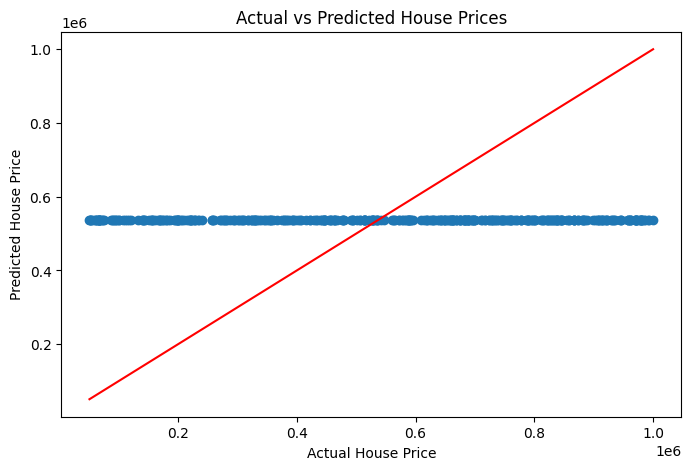

In [17]:
#Visualise actual vs predicted values
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")

plt.show()

In [18]:
#Predict a new example and conclusion
# Create a new house example
new_house = pd.DataFrame({
    'Area': [2500]
})

# Predict house price
new_prediction = model.predict(new_house)

print("New House Area:", 2500)

print("Predicted House Price:",
      new_prediction[0])

New House Area: 2500
Predicted House Price: 536234.0267891428
